# `Лекция 07. Self-Supervised Vision Models`

## `Занятие провел: Оганов Александр (tg: @welmud)`

## `Материалы составил: Оганов Александр (tg: @welmud)`

### `Москва, Осенний семестр 2026`

Источники:

- **DINO**: [Mathilde Caron et al., 2021](https://arxiv.org/abs/2104.14294), примерно 13000 цитирований

- **DINOv2**: [Maxime Oquab et al., 2023](https://arxiv.org/abs/2304.07193), примерно 13000 цитирований

- **DINOv3**: [Oriane Siméoni et al., 2025](https://arxiv.org/abs/2508.10104), примерно 1600 цитирований

- **Averaging Weights Leads to Wider Optima and Better Generalization**: [Pavel Izmailov et al., 2018](https://arxiv.org/abs/1803.05407), примерно 2700 цитирований

- [GitHub реализация DINOv1](https://github.com/facebookresearch/dino)

- [GitHub реализация DINOv2](https://github.com/facebookresearch/dinov2)

- [GitHub реализация DINOv3](https://github.com/facebookresearch/dinov3)

---

## Дистилляция без явного учителя: DINO (2021)

[Mathilde Caron et al., 2021](https://arxiv.org/abs/2104.14294), примерно 13000 цитирований

Раньше мы обучали модели для решения конкретных задач: **классификация**, **сегментация**, **детекция**. Иногда так оказывается, что **векторные представления**, полученные с помощью "хорошей модели", намного важнее, чем сама модель. При этом задача получения хорошего векторного представления, которое содержит нужную информацию, более общая, чем конкретная задача.

#### <font color='Orange'>**Вопрос:**</font> Какие модели для получения эмбеддингов слов вы знаете? Какие из них лучше всего сейчас работают?

Ответ:

Если не учитывать классические методы, такие как word2vec и другие, то, скорее всего, BERT и другие трансформерные модели.

####

Большинство современных интересных результатов в области глубокого обучения были получены с помощью трансформеров. Давайте вспомним, что отличает трансформеры от других моделей.

#### <font color='Orange'>**Вопрос:**</font> Благодаря чему трансформерные архитектуры достигают превосходных результатов? Можете считать, что мы сейчас обсуждаем BERT.
Ответ:

Во-первых, архитектура, в частности **механизм внимания** (мы не будем останавливаться на смыслах и интерпретациях). 

Во-вторых, **self-supervised pretraining** (в случае BERT мы решаем задачу маскирования) благодаря которому нам не нужны миллиарды размеченных данных для большой архитектуры.

####

Теперь представим, что стоит задача получения **"хороших" векторных представлений изображений**. Осталось понять, чему должно удовлетворять "хорошее" векторное представление изображения. В общей постановке под "хорошим" можно понимать много разных вещей, например:

- Объекты одного класса были ближе, а разных &ndash; дальше;
- Линейная интерполяция в латентном пространстве делает плавный переход между изображениями.

Мы бы хотели получить такие векторные представления, чтобы **для разных аугментаций одного изображения**, например, размера, изменения разрешения, поворота **получались похожие векторные представления**. Список аугментаций можно расширить до:

1) RandomHorizontalFlip;
2) ColorJitter;
3) RandomResizedCrop;
4) GaussianBlur;
5) Solarization.

Осталось понять, как выучить такую модель. Если мы возьмем изображение и построим по нему разные аугментации, например, одни будут выделять локальные изображения (с RandomResizedCrop), а другие глобальные (без RandomResizedCrop), то мы ожидаем, что модель должна выдавать похожие "хорошие" эмбеддинги. 

#### <font color='Orange'>**Вопрос:**</font> Как вы думаете получить "хороший" эмбеддинг, который совпадает с настоящим изображением проще через локальное или глобальное изображение?

Ответ:

Многое, конечно, зависит от аугментаций, но кажется получить эмбеддинг котенка, проще когда видно и хвост и ушки с лапками. Мы предполагаем, что наши модели умеют извлекать информацию из изображений, даже из глобального контекста, так как мы всё строим на базе трансформерной архитектуры (например ViT).

####

Получается, мы хотим, чтобы вектор $f(x^{\text{local}})$ был похож на $f(x^\text{global})$, где $f(\cdot)$ &ndash; нейросеть, а $x^{\text{local}}$ и $x^\text{global}$ &ndash; соответственно локальные и глобальные изображения.

Похожий метод, только намного аккуратнее и точнее реализован в статье [Emerging Properties in Self-Supervised Vision Transformers](https://arxiv.org/abs/2104.14294).

#### <font color='Orange'>**Вопрос:**</font> Почему нам не подходит **knowledge distillation** в стандартном варианте?

Ответ:

У нас нет модели учителя, мы лишь знаем, что, возможно, задача для $x^\text{global}$ проще и информативнее.

####

Представим, что у нас есть модель **Teacher**, которая хотя бы чуть лучше решает задачу, чем **Student**. Пусть обе нейронные сети имеют одну архитектуру, например, Vision Transformer.

$g_{\theta_s}$ &ndash; модель **Student**,  $g_{\theta_t}$ &ndash; модель **Teacher**.

Для любой модели мы можем выдавать на выходе какой-то вектор для входа $x$, далее мы можем применить $\mathrm{Softmax}$ с температурой и получить распределение вероятностей $P_t(x)$ и $P_s(x)$. Авторы предлагают оптимизировать следующую функцию потерь:


\begin{equation}
    \min_{\theta_s} \sum_{x \in \{x_1^g, x_2^g\}} \sum_{x' \in V, x' \neq x} CE(P_t(x), P_s(x')),
\end{equation}
где $x_1^g$, $x_2^g$ &ndash; глобальные аугментации одного изображения, $V$ &ndash; набор хотя бы двух глобальных изображений и какого-то количества локальных (может быть, даже без них).

Получается, что модель **Teacher** всегда видит только глобальные аугментации (более простые примеры). Остается вопрос, откуда взять модель **Teacher**.

В работе авторы предлагают **knowledge DIstillation with NO labels** или кратко **DINO**, то есть дистилляцию без меток. Алгоритм обучения представлен ниже:

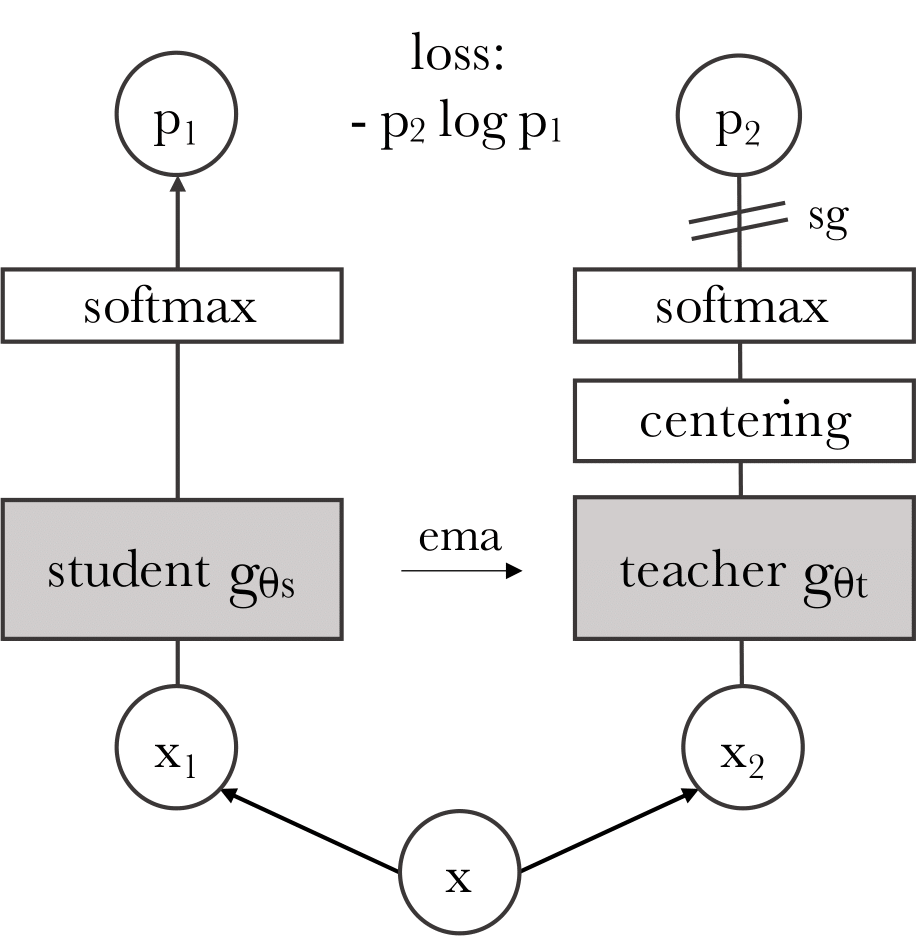

Self-distillation with no labels | [Источник](https://arxiv.org/abs/2104.14294)

Модель **Teacher** видит более простые примеры, кроме того, является EMA-сглаженной версией **Student**, поэтому она всегда чуть лучше. Подход, когда **Teacher** получается из **Student** часто называют самодистилляцией.

Заметим, что у задачи есть наивное решение &ndash; возвращать всегда какую-либо константу. Эту проблему часто называют схлопыванием (collapse). Авторы, ещё отмечают, что схлопывание может возникнуть, когда модель начинает больше учитывать какую-то одну координату. 

То есть мы не хотим получать одинаковый выход, но и не хотим, чтобы в выходе изменялась только одна координата. Для решения этой проблемы есть разные техники. Для борьбы с учётом одной координаты, авторы, предлагают добавлять к выходу модели смещение $c$:
\begin{equation}
    \mathrm{Centering}: g_{\theta_t}(x) = g_{\theta_t}(x) + c.
\end{equation}

$c$ считаем также с EMA-сглаживанием:
\begin{equation}
    c = mc + (1 - m) \frac{1}{B}\sum_{i=1}^B g_{\theta_t}(x_i).
\end{equation}


Для борьбы с одинаковым выходом, авторы подбирают расписание температуры **Teacher**, они берут $\tau_t$ около 0,04 (если взять слишком много, модель схлопнется, взять 0 &ndash; будет плохо учиться). 

Подробный анализ collapse представлен в секции 5.3.

Основные детали:

- $x_1$ и $x_2$ изображения, полученные с помощью различных аугментаций из изображения $x$; 
- Модели учителя и студента имеют одну архитектуру;
- Веса учителя не обучаются и являются EMA-глаженными весами студента;
- **sg** означает stop grad, то есть градиенты не проходят в модель учителя;
- Обучается на кросс-энтропию, так как наша цель, чтобы  ученик был похож по распределению на учителя;
- Важно, что $p_2 \log p_1$, а не наоборот, так как мы учим именно студента;
- Блок centering, центрирует выход teacher с учётом истории на прошлых батчах;
- Низкая температура для учителя (sharpening);
- Датасет ImageNet-1k (1,3 миллиона изображений).

**Напоминание**. EMA-веса модели определяются так: $x_{\text{ema}}^{k + 1} = m \cdot x_{\text{ema}}^{k} + (1 - m) x^{k + 1}$, где $x^k$ веса модели после $k$ итераций обучения. На практике на EMA-весах **очень часто лучше метрики**. В работе [Pavel Izmailov et al., 2018](https://arxiv.org/abs/1803.05407) показывается связь между сглаживанием весов и широким минимумом.

Задача и идея выглядят сложными, но авторы уже выпустили DINOv2, DINOv3 и называют модель DINOv1 &ndash; статьёй с целью Proof of Concept (проверка идеи). Далее мы обсудим DINOv2 и DINOv3.

Реализация DINOv1 при этом аккуратно выполнена и доступна на [GitHub](https://github.com/facebookresearch/dino). 

### DINOv1 результаты:

Классическим способом оценки моделей, которые извлекают признаки, является обучение какого-то простого классификатора на полученных признаках. Если пространство признаков **"хорошее"**, то даже KNN хватит. Ниже качество классификации ImageNet и сравнение способов выбора учителя:

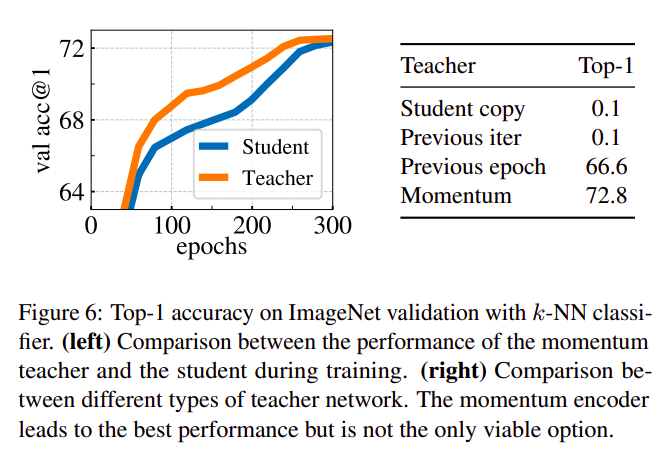

[Источник](https://arxiv.org/abs/2104.14294)

Вспомним ради чего мы все начали, а именно вспомним о задаче сегментации. Естественно в статье множество результатов, но нас интересует именно сегментация. Если мы хотим сегментировать объект, то наша цель выделить все пиксели связанные с ним. Для начала стоит понять, как сегментировать "самый важный" объект на изображении? Для этого стоит посмотреть self-attention для `[CLS]` токена. Пример ниже:

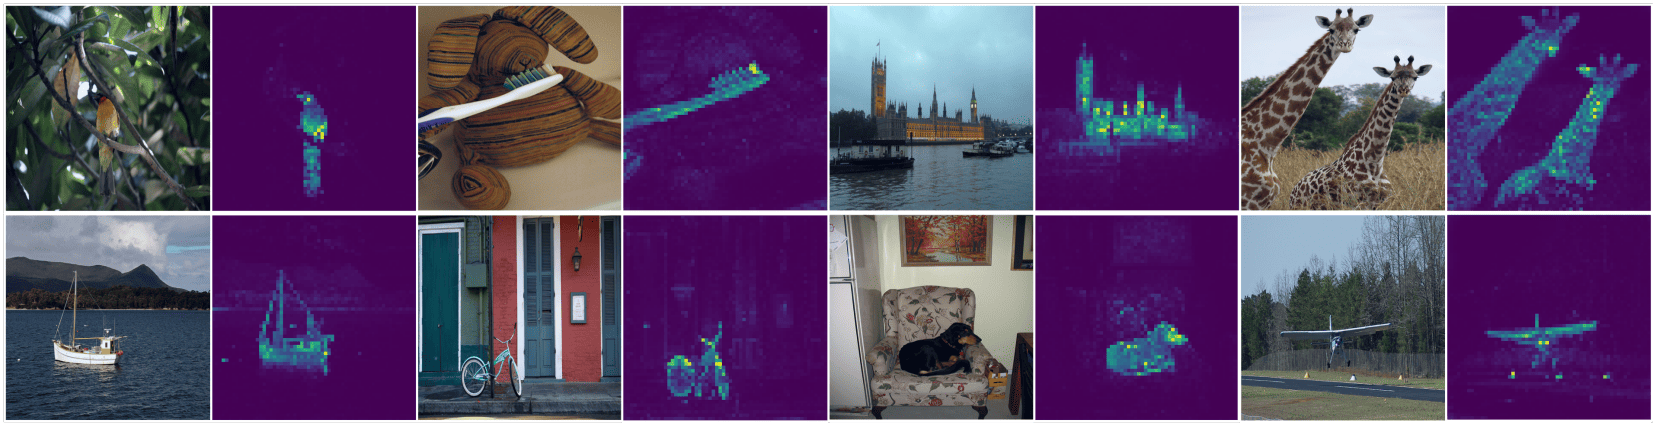

Self-attention from a Vision Transformer with 8 × 8 patches trained with no supervision | [Источник](https://arxiv.org/abs/2104.14294)

При этом если использовать выход self-attention для `[CLS]`, то сегментационная маска получается лучше, чем для некоторых supervised методов.

#### <font color='Orange'>**Вопрос:**</font> Мы знаем, что разные головы attention извлекают разные контексты, как вы думаете как будут выглядеть self-attention для разных голов?
Ответ: 

Должны извлекаться разные части главного объекта или разные главные объекты.

####

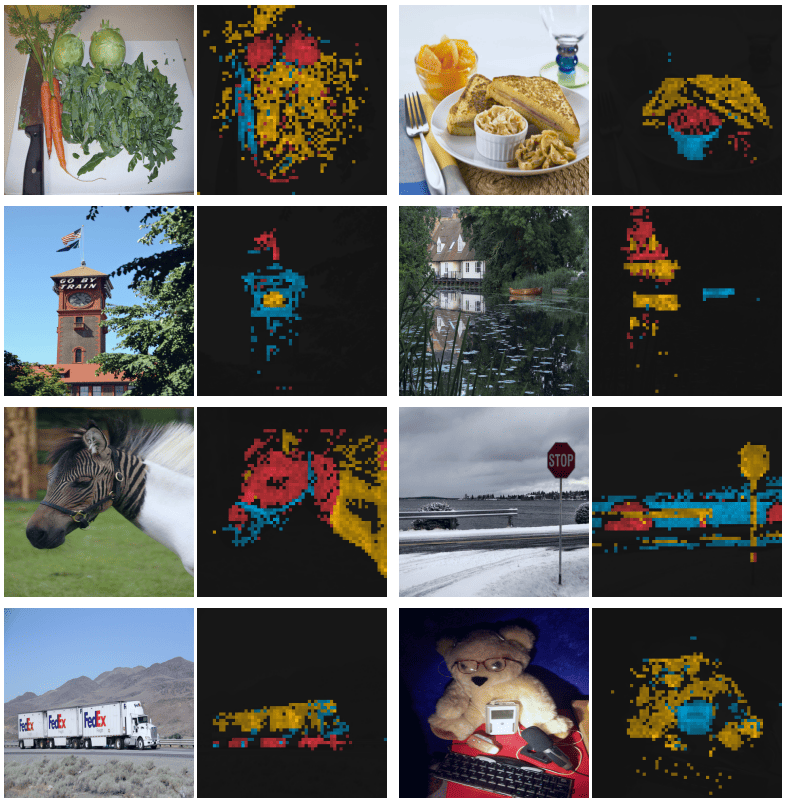

Attention maps from multiple heads | [Источник](https://arxiv.org/abs/2104.14294)

Также мы можем выделить какую-то конкретную точку (патч) и отследить значения в self-attention для нее.

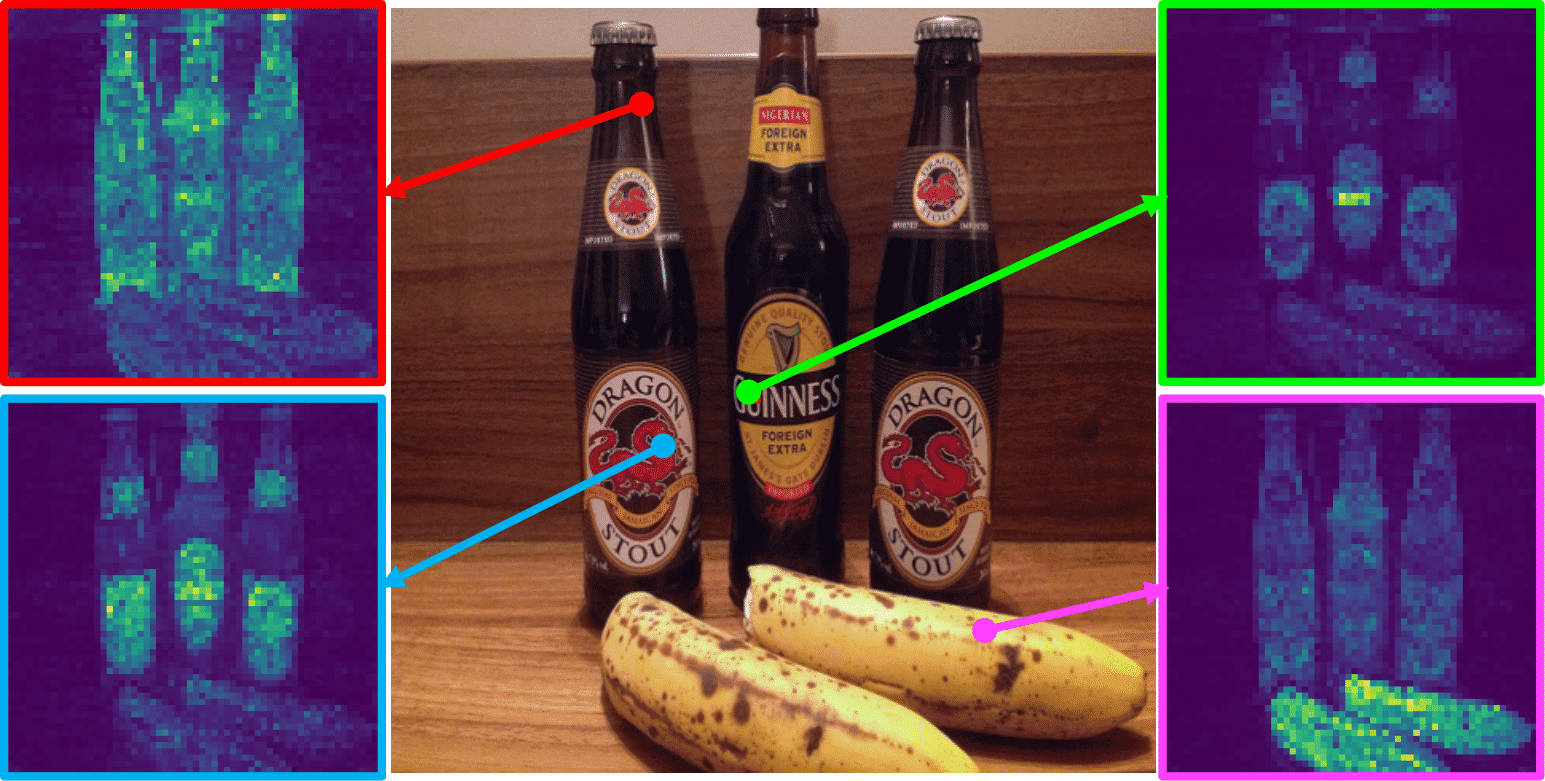

Self-attention for a set of reference points | [Источник](https://arxiv.org/abs/2104.14294)

## DINOv2 (2023)

[Maxime Oquab et al., 2023](https://arxiv.org/abs/2304.07193), примерно 13000 цитирований на октябрь 2026 года и 5000 на октябрь 2025 года.


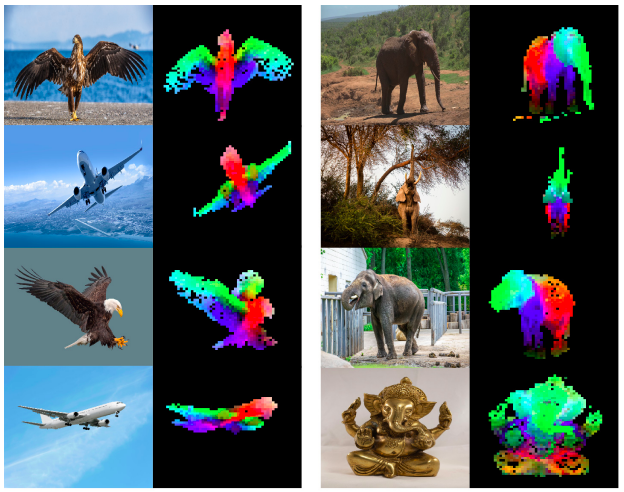

Визуализация эмбеддингов патчей через PCA | [Источник](https://arxiv.org/abs/2304.07193)

#### <font color='Orange'>**Вопрос:**</font> Что мы можем ещё хотят от векторных представлений?
Ответ:

Например, чтобы пачти соотвествующие частям изображений схожего "смысла" были похожи как напримере выше.

####

### Больше данных

Если мы хотим лучше качество, нам нужно взять модель с большим числом параметров. Для обучения модели с большим числом параметров нужно много данных. Также авторы отмечают, что методы self-supervised learning очень зависимы от чистоты данных.

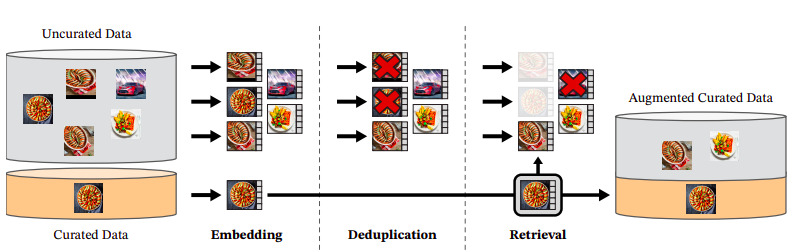

[Источник](https://arxiv.org/abs/2304.07193)

В итоге был собран датасет  LVD-142M, который содержит 142 миллиона изображений. Для DINOv1 использовали  ImageNet-1k (1.3 миллиона изображений).

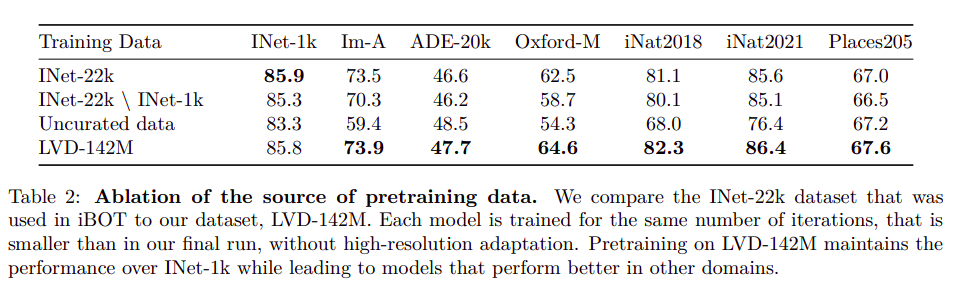

[Источник](https://arxiv.org/abs/2304.07193)

### Image-level objective

Раньше мы оптимизировали:

\begin{equation}
    \mathcal{L}_{\mathrm{DINO}} = \sum_{x \in \{x_1^g, x_2^g\}} \sum_{x' \in V, x' \neq x} CE(P_t(x), P_s(x')).
\end{equation}

Эта функция потерь хорошая для выучивания `[CLS]` токена. 

### Patch-level objective

Усложним задачу ученику, добавим маскирование отдельных патчей для входа **Student** (не **Teacher**!). Цель: выходы для замаскированных патчей **Student**, должны быть похожи на выходы для этих же патчей **Teacher**.

\begin{equation}
\mathcal{L}_{\text{iBOT}} = - \sum p_{ti} \log p_{si},
\end{equation}
где мы суммируем только по маскированным патчам. iBOT &ndash; **i**mage **B**ERT pre-training with **O**nline **T**okenizer.

### Sinkhorn-Knopp centering

Отказ от центрирования как в DINO для $\mathcal{L}_{\mathrm{DINO}}$ и $\mathcal{L}_{\mathrm{iBOT}}$ в пользу центрирования Sinkhorn-Knopp.

### Untying head weights between both objectives

Для получения вероятностей в каждом лоссе используются MLP. Лучше, если в этих MLP есть общие веса.

### KoLeo regularizer

Частой идеей для self-supervised методов является предположение, что представления разных изображений должны быть далеки друг от друга.

#### <font color='Orange'>**Вопрос:**</font> Как можно заложить в фукнцию потерь предположение выше?
Ответ:

Для набора векторов $(x_1, \ldots, x_n)$ определим

\begin{equation}
\mathcal{L}_{\mathrm{koleo}} = - \frac{1}{n}\sum_{i=1}^n \log d_{n, i},
\end{equation}
где $d_{n, i} = \min_{j \neq i} \|\frac{x_i}{\|x_i\|} - \frac{x_j}{\|x_j\|}\|$, сами вектора ещё обычно сначала нормируются.

####

### Adapting the resolution

Мы бы хотели учить в большом разрешении, но такое обучение будет дорогим и в начале не особо имеет смысла, так как модели не научились извлекать мелкие детали.

Поэтому авторы использую высокое разрешение (512$\times$512) только в конце обучения, а начинают с разрешения (224$\times$224).

Так в конце обучения мы повышаем качество признаков для маленьких деталей, которые раньше просто не замечали.

Ablation в Table 1 оригинальной статьи.

### Эффективность:


Достаточно много идей, инженерии и еще больше ablation study. Кроме того, крайне много эффективного кода:

- Fast and memory-efficient attention;

- Efficient stochastic depth (иногда проходить только по residual connection);

- Sequence packing (работа с последовательностями разной длинны);

- Fully-Sharded Data Parallel (FSDP).

#### <font color='Orange'>**Вопрос:**</font> Учить с нуля большие модели на больших наборах данных дорого. Как получить семейство моделей разного размера хорошего качества?
Ответ:

Обучим самую большую модель на примерно 1 млрд. параметров, а дальше будем использовать её как замороженный **Teacher** для более маленьких моделей.

####

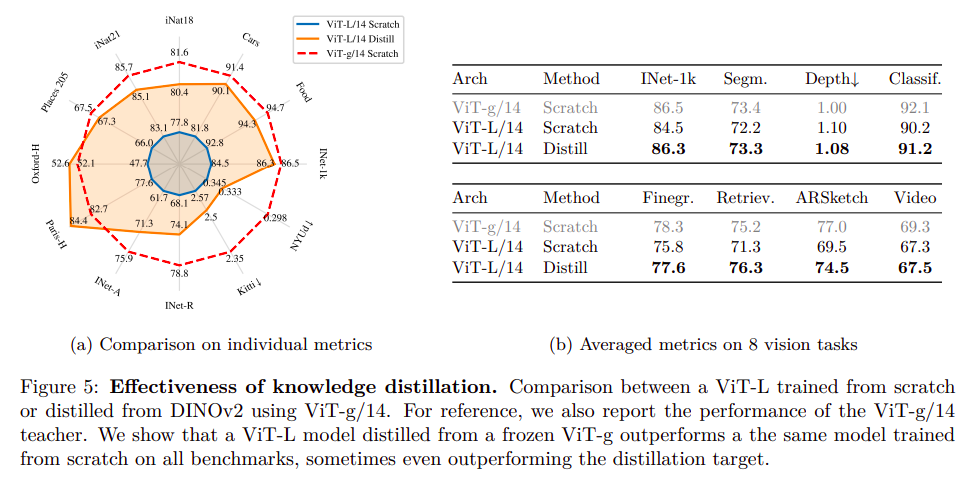

[Источник](https://arxiv.org/abs/2304.07193)

### DINOv2 результаты

- На классификации модель лучше, чем CLIP, OpenCLIP и другие Weakly supervised методы;

- Можно применять fine-tuning и получить качество сравнимое с SOTA.

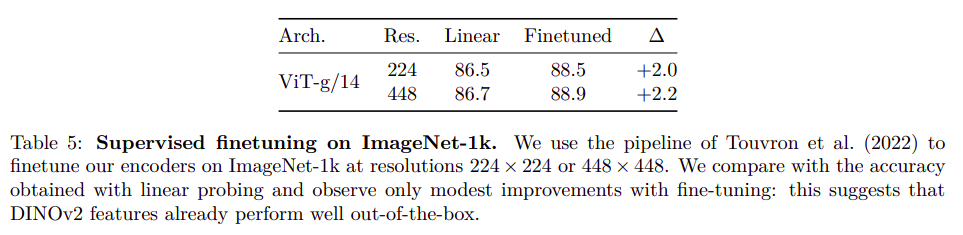

[Источник](https://arxiv.org/abs/2304.07193)

Для задачи классификации, вообще говоря, нам не нужно было выучивать что-то сложнее, чем `[CLS]` токен. Выше мы видели, что изменения повышают качество, однако, это не целевое применение модели. Различия должны появится в более сложных задачах.

#### <font color='Orange'>**Вопрос:**</font> Какие более сложные задачи вы знаете?
Ответ:

Такими задачами можно назвать те, где нам нужно имееть представление обо всей сцене: семантическая сегментация, задача оценки глубины.

####

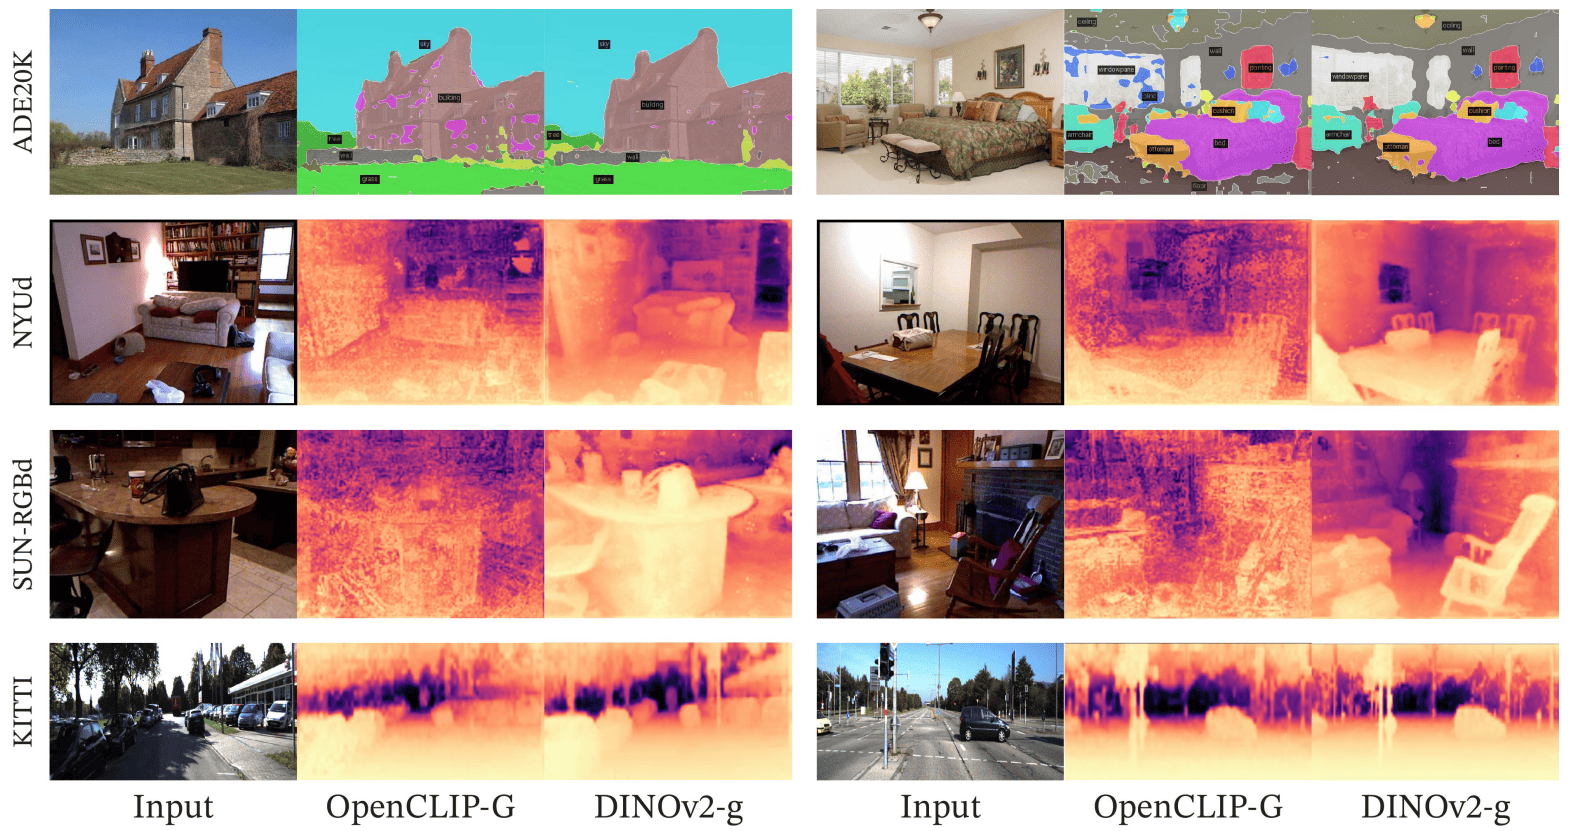

Segmentation and depth estimation with linear classifiers. | [Источник](https://arxiv.org/abs/2304.07193)

Авторы предложили также посмотреть, как именно выглядят векторные представления патчей. Для этого предлагается обучить PCA и понизить размерность для 3. Пример был выше. Из него видно, что представления семантически похожих частей разных изображений имеют один цвет, а значит близкие вектора.

Это позволяет нам матчить различные точки изображений.

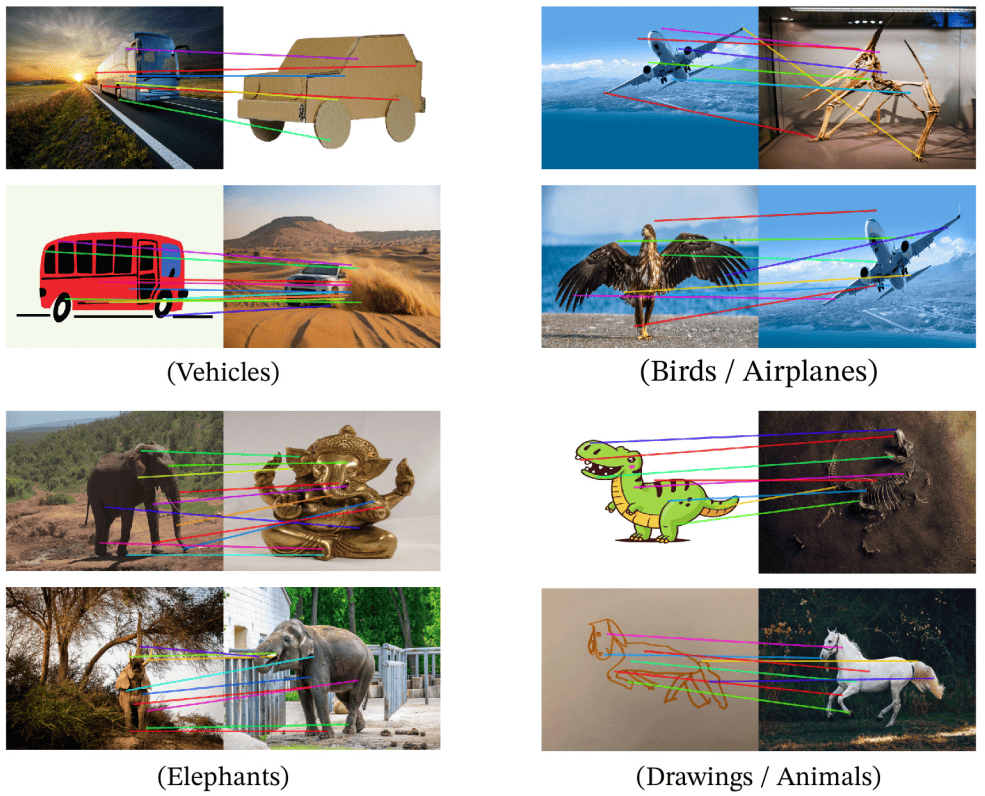

Matching across images. | [Источник](https://arxiv.org/abs/2304.07193)

## DINOv3 (2025)

[Oriane Siméoni et al., 2025](https://arxiv.org/abs/2508.10104), примерно 1600 цирований; 34 цитирований на момемент 5 октября 2025, дата публикации 13 августа 2025

#### Данные

Собран датасет LVD-1689M вместо LVD-142M. Процедура отбора изображений стала сложнее и содержит предобработку с помощью DINOv2 (Ablation Table 1).

#### Архитектура

Мы снова учим только самую большую модель, далее дистиллируем. Только модель стала почти 7 млрд параметров (Table 2).

Также добавлены RoPE эмбеддинги.

#### Основная идея

Основное идейное изменение &ndash; матчить матрицу Грама признаков студента с матрицей Грама признаков учителя:

$$\mathcal{L}_{\text{Gram}} = \| X_S \cdot X_S^\top - X_G \cdot X_G^\top \|_F^2,$$
где $X_s \in \mathbb{R}^{P\times d}$, $P$ &ndash; число патчей, $d$ &ndash; размерность векторного представления.

Брать признаки для матрица Грамма учителя с последних итераций будет работать плохо, так как модель могла уже испортить признаки. Авторы берут признаки с итерации 100 или 200 тысяч. Подробнее можно почитать в Секции 4.3 оригинальной статьи.


Графики обучения представлены на Figure 7. Добавляем матрицу Грама в самом конце обучения.

Матрицы Грама призваны сделать пространство признаков более гладким. Для этого авторы используют следующий трюк: подают на вход учителю изображение в высоком разрешении, считают признаки, а потом делают downsampling, чтобы они стали более "гладкие". Такой трюк позволяет ещё улучшить качество.

Если дополнительно применить много инженерных трюков, взять большие архитектуры, подобрать параметры оптимизации и много всего разного, то можно получить:

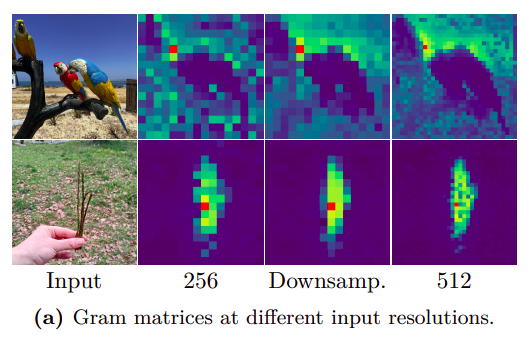

[Источник](https://arxiv.org/abs/2508.10104)

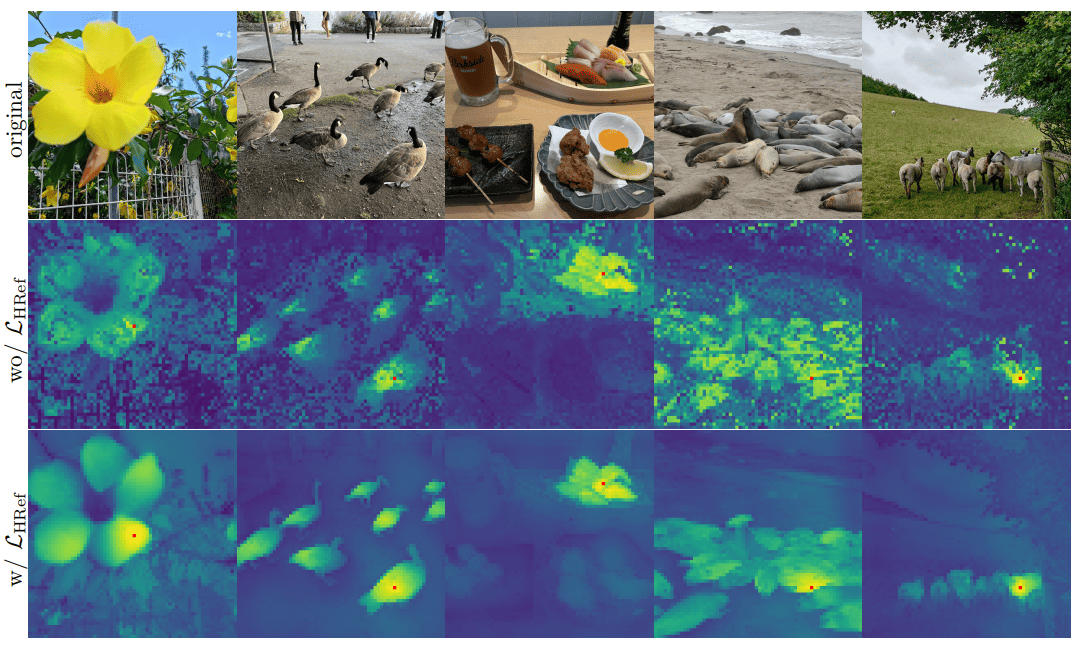

Cosine similarity maps obtained with DINOv3 output features | [Источник](https://arxiv.org/abs/2508.10104)

Если дополнительно применить много инженерных трюков, взять большие архитектуры, подобрать параметры о/птимизации и много всего разного, то можно получить:

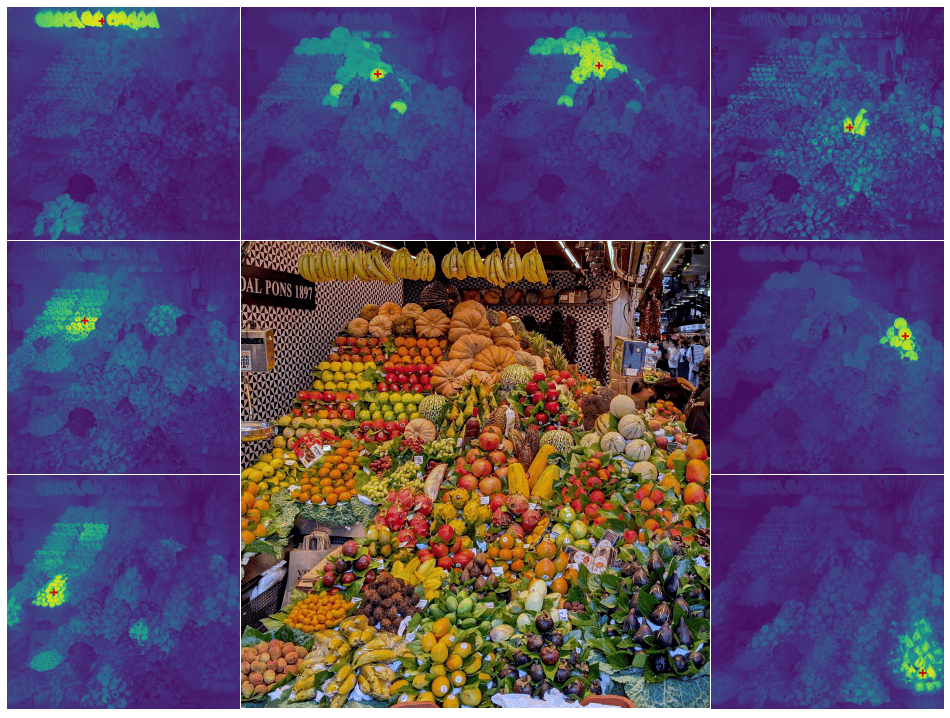

High-resolution dense features | [Источник](https://arxiv.org/abs/2508.10104)

### Foundational model

DINOv3 решает задачи:
- Classification
- Semantic segmentation
- Object Detection
- Monocular Depth Estimation
- 3D Correspondence Estimation
- Unsupervised Object Discovery
- Video Segmentation Tracking
- Video Classification
- Instance Recognition


Также авторы добавили возможность поддержки текста, назвали модель `dino.txt`.

Тажке авторы показали, что модель способна обучаться на данных со спутника: оценивать высоту, сегментировать и иное.